# Session 4 — Filters on skin lesions: classes, Gaussian blur, Canny vs Sobel

Three questions from the homework, answered on the MILK10k dermoscopic photographs:

1. **Filters across diagnosis classes.** Run a bank of filters over benign and malignant lesions. Do edges and
   textures look or measure differently?
2. **Gaussian blur.** What does `sigma` in `scipy.ndimage.gaussian_filter` mean, and what happens to edges as it grows?
3. **Canny vs Sobel.** Implement Canny as a function and compare it with Sobel on one image.

All filters are written in `src/milk10k/filters.py` (tested in `tests/test_filters.py`); this notebook calls them.
Images come from the **training** split only, so nothing here touches validation or test lesions.
A short answer sheet is at the end (§5).

In [1]:
# --- setup: find the repo root from wherever the notebook is opened -----------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import milk10k as mk
from milk10k import features as F

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from scipy import ndimage, stats
from sklearn.metrics import roc_auc_score
from milk10k import filters as flt

SEED = mk.config.SEED
BLUE, ORANGE, AQUA = mk.BLUE, mk.ORANGE, mk.AQUA
IMG = mk.config.IMAGE_DIR
OUT = mk.config.ARTIFACT_DIR / "session04"
OUT.mkdir(parents=True, exist_ok=True)
BANK = flt.kernel_bank()

train = F.load_lesion_splits()["train"]
train = train[train["diagnosis_1"].isin(["Benign", "Malignant"])].reset_index(drop=True)
rng = np.random.default_rng(SEED)
pick = lambda cls, n: train[train.diagnosis_1 == cls].sample(n, random_state=SEED)

def gray_of(isic_id, size=(200, 150)):
    """Simple-average grayscale (as in Sessions 2 and 5), float 0-255, shape (h, w)."""
    return F.load_rgb(IMG / f"{isic_id}.jpg", size).mean(axis=2)

def core(a):
    """Central 60 % of an array: drops the black dermoscope vignette and corner artefacts."""
    h, w = a.shape
    return a[h // 5: -(h // 5), w // 5: -(w // 5)]

print(f"train lesions: {train.diagnosis_1.value_counts().to_dict()}")

train lesions: {'Malignant': 2595, 'Benign': 1058}


## 1. A filter bank on benign vs malignant lesions

Every filter is a small kernel slid over the grayscale image (`ndimage.correlate`: multiply the neighbourhood by the kernel
and add). What changes is the kernel:

| filter | what its kernel looks for |
|---|---|
| Sobel x / y | brightness *change* left→right / top→bottom (edges) |
| Laplacian | change of the change: bright or dark spots, ridges, fine texture |
| Gabor 0° / 45° / 90° | repeating stripes of a given orientation and width (~8 px) |
| Difference of Gaussians (DoG) | blobs a few pixels wide (centre minus surround) |

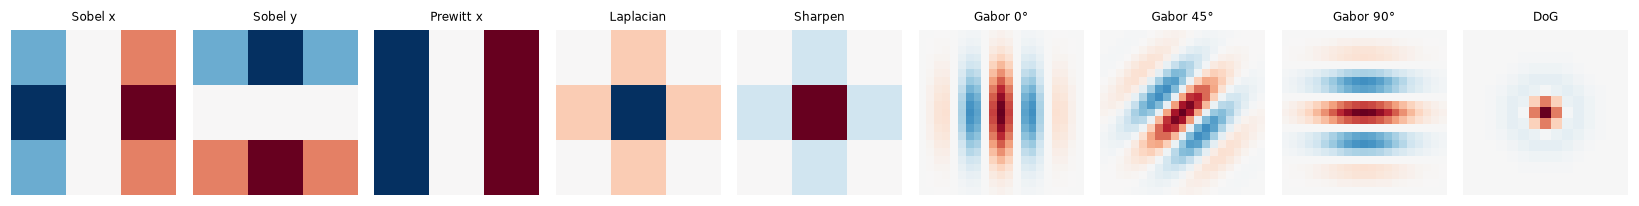

In [2]:
fig, axes = plt.subplots(1, len(BANK), figsize=(15, 1.9))
for ax, (name, k) in zip(axes, BANK.items()):
    ax.imshow(k, cmap="RdBu_r", vmin=-np.abs(k).max(), vmax=np.abs(k).max())
    ax.set_title(name, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

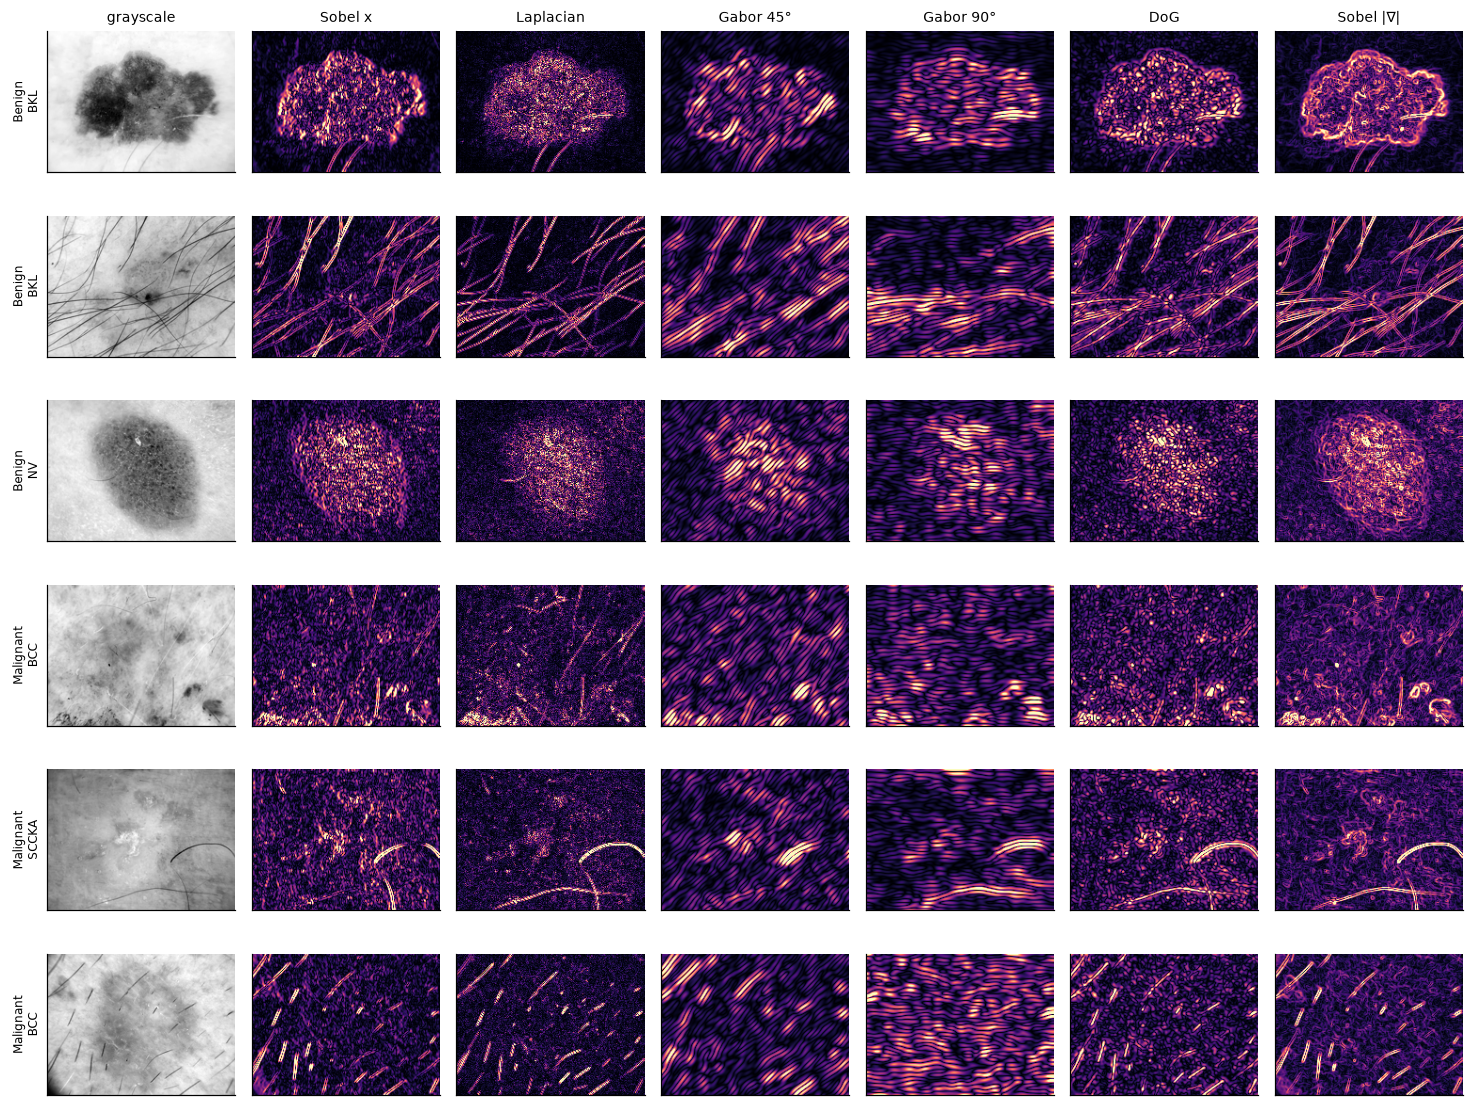

In [3]:
show = ["Sobel x", "Laplacian", "Gabor 45°", "Gabor 90°", "DoG"]
cases = pd.concat([pick("Benign", 3), pick("Malignant", 3)])
fig, axes = plt.subplots(len(cases), 1 + len(show) + 1, figsize=(13.5, 1.75 * len(cases)))
for r, (_, row) in enumerate(cases.iterrows()):
    g = gray_of(row.derm_id)
    axes[r, 0].imshow(g, cmap="gray"); axes[r, 0].set_ylabel(f"{row.diagnosis_1}\n{row.dx}", fontsize=8)
    mags = [np.abs(flt.apply_kernel(g, BANK[n])) for n in show] + [flt.sobel_gradients(g)[2]]
    for c, (n, m) in enumerate(zip(show + ["Sobel |∇|"], mags), start=1):
        axes[r, c].imshow(m, cmap="magma", vmax=np.percentile(m, 99))
        if r == 0: axes[r, c].set_title(n, fontsize=9)
    if r == 0: axes[r, 0].set_title("grayscale", fontsize=9)
    for a in axes[r]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

Three random benign and three random malignant lesions (fixed seed, not cherry-picked). Eyeballing six images is not
evidence, so the next cell measures the same filters on **150 benign and 150 malignant** training lesions.
Each number is averaged over the central 60 % of the image so the black dermoscope rim does not count as an "edge".
`edge density / contrast` divides by the image's grayscale standard deviation, to separate *texture* from plain *contrast*.

In [4]:
def describe(g):
    sob = flt.sobel_gradients(g)[2]
    resp = lambda k: flt.apply_kernel(g, BANK[k])
    c = core(g)
    return {
        "edge density (Sobel)":    core(sob).mean(),
        "edge density / contrast": core(sob).mean() / c.std(),
        "Laplacian variance":      core(resp("Laplacian")).var(),
        "Gabor energy":            np.mean([np.abs(core(resp(k))).mean() for k in ("Gabor 0°", "Gabor 45°", "Gabor 90°")]),
        "DoG energy":              np.abs(core(resp("DoG"))).mean(),
        "Canny edge fraction":     core(flt.canny(g, sigma=1.5)).mean(),
        "brightness (mean)":       c.mean(),
        "contrast (std)":          c.std(),
    }

N = 150
sample = pd.concat([pick("Benign", N), pick("Malignant", N)]).reset_index(drop=True)
t0 = time.perf_counter()
grays = [gray_of(i) for i in sample.derm_id]
stats_df = pd.DataFrame([describe(g) for g in grays])
stats_df["label"] = sample.diagnosis_1.to_numpy()
is_mal = (stats_df.label == "Malignant").to_numpy()
print(f"{len(sample)} images in {time.perf_counter() - t0:.0f} s")

rows = []
for col in stats_df.columns[:-1]:
    v = stats_df[col].to_numpy()
    rows.append({"measure": col,
                 "benign median": np.median(v[~is_mal]), "malignant median": np.median(v[is_mal]),
                 "AUC (malignant higher)": roc_auc_score(is_mal, v),
                 "Mann-Whitney p": stats.mannwhitneyu(v[is_mal], v[~is_mal]).pvalue})
filter_table = pd.DataFrame(rows).set_index("measure")
filter_table.round(3).to_csv(OUT / "filter_class_stats.csv")
filter_table.round(4)

300 images in 19 s


,benign median,malignant median,AUC (malignant higher),Mann-Whitney p
measure,,,,
edge density (Sobel),34.4360,27.4087,0.3809,0.0004
edge density / contrast,1.5363,2.0326,0.6920,0.0000
Laplacian variance,151.6800,101.1062,0.3937,0.0015
Gabor energy,64.7950,54.1219,0.4355,0.0533
DoG energy,1.6792,1.4603,0.4250,0.0247
Canny edge fraction,0.1798,0.1906,0.5802,0.0163
brightness (mean),135.7762,150.1667,0.6924,0.0000
contrast (std),25.8772,15.2108,0.2963,0.0000


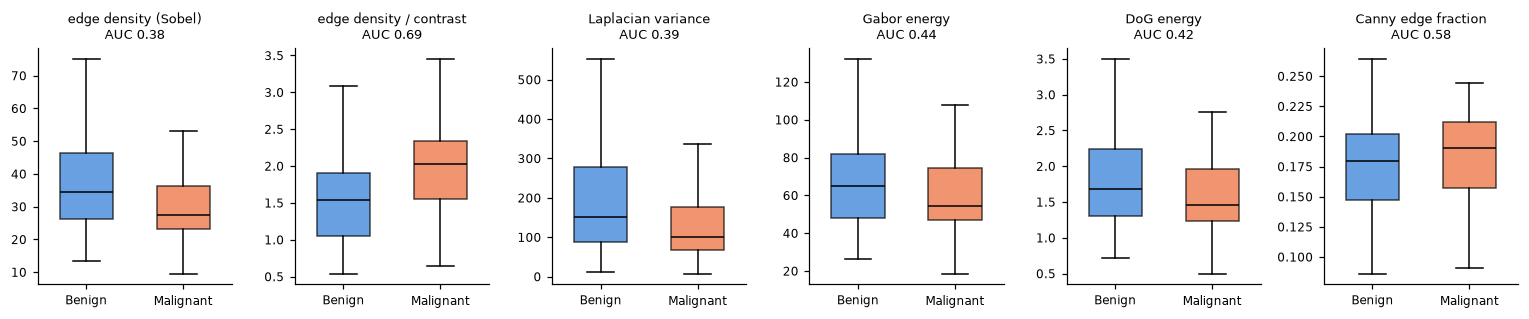

In [5]:
keys = ["edge density (Sobel)", "edge density / contrast", "Laplacian variance", "Gabor energy", "DoG energy", "Canny edge fraction"]
fig, axes = plt.subplots(1, len(keys), figsize=(14, 3))
for ax, k in zip(axes, keys):
    data = [stats_df.loc[~is_mal, k], stats_df.loc[is_mal, k]]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False, tick_labels=["Benign", "Malignant"])
    for patch, col in zip(bp["boxes"], [BLUE, ORANGE]): patch.set_facecolor(col); patch.set_alpha(0.7)
    for med in bp["medians"]: med.set_color("black")
    ax.set_title(f"{k}\nAUC {filter_table.loc[k, 'AUC (malignant higher)']:.2f}", fontsize=8.5)
    ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

**Is it just these 300 images?** The same measures on **all 3,653 benign and malignant training lesions** (same grayscale,
same central crop), with a bootstrap 95 % interval on each AUC. The two colour rows (whole-image Session 5 features, already
cached in `artifacts/features`) are a yardstick: how well do plain colour numbers separate the classes?

In [6]:
from concurrent.futures import ThreadPoolExecutor

def core_stats(isic_id):
    g = gray_of(isic_id); c = core(g); sob = core(flt.sobel_gradients(g)[2])
    return [sob.mean(), sob.mean() / c.std(), core(flt.apply_kernel(g, BANK["Laplacian"])).var(), c.std(), c.mean()]

t0 = time.perf_counter()
with ThreadPoolExecutor(8) as pool:
    core_vals = pd.DataFrame(list(pool.map(core_stats, train.derm_id)),
                             columns=["edge density (Sobel)", "edge density / contrast", "Laplacian variance",
                                      "contrast (std)", "brightness (mean)"])
allf = F.feature_table(train.derm_id, cache=F.FEATURE_DIR / "features.npz").loc[train.derm_id].reset_index(drop=True)
core_vals["colour: mean blue (whole image)"] = allf["mean_B"].to_numpy()
core_vals["colour: saturation (whole image)"] = allf["sat_mean"].to_numpy()
full_mal = (train.diagnosis_1 == "Malignant").to_numpy()
print(f"{len(train):,} lesions in {time.perf_counter() - t0:.0f} s")

boot = np.random.default_rng(SEED).integers(0, len(train), (300, len(train)))
full = []
for col in core_vals:
    v = core_vals[col].to_numpy()
    ci = np.percentile([roc_auc_score(full_mal[i], v[i]) for i in boot], [2.5, 97.5])
    full.append({"measure": col, "benign median": np.median(v[~full_mal]), "malignant median": np.median(v[full_mal]),
                 "AUC (malignant higher)": roc_auc_score(full_mal, v), "95% CI": f"[{ci[0]:.2f}, {ci[1]:.2f}]"})
full_table = pd.DataFrame(full).set_index("measure")
full_table.round(3).to_csv(OUT / "filter_class_stats_full_train.csv")
full_table.round(3)

3,653 lesions in 2 s


,benign median,malignant median,AUC (malignant higher),95% CI
measure,,,,
edge density (Sobel),33.106,28.022,0.402,"[0.38, 0.42]"
edge density / contrast,1.402,1.929,0.696,"[0.68, 0.72]"
Laplacian variance,140.835,101.214,0.414,"[0.40, 0.44]"
contrast (std),25.791,15.036,0.295,"[0.28, 0.31]"
brightness (mean),134.959,149.749,0.686,"[0.66, 0.71]"
colour: mean blue (whole image),140.365,134.544,0.421,"[0.40, 0.44]"
colour: saturation (whole image),0.209,0.251,0.616,"[0.59, 0.64]"


In [7]:
import torch, torchvision
try:
    net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
    learned = net.conv1.weight.detach().clone()                 # (64 filters, 3 colour channels, 7, 7)
    source = "ResNet-18 (ImageNet) conv1"
except Exception as e:                                          # offline: say so, fall back to the Gabor bank
    learned, source = None, f"unavailable ({type(e).__name__})"
print("learned filters:", source, None if learned is None else tuple(learned.shape))

learned filters: ResNet-18 (ImageNet) conv1 (64, 3, 7, 7)


### Learned filters

The hand-built bank is a guess about what matters. A convolutional network *learns* its first-layer kernels from data.
Below are the 64 first-layer kernels (7×7, three colour channels) of ResNet-18 trained on ImageNet — not on skin lesions.
Each is shown as a small colour image; AUC under each tile is how well that single filter's mean absolute response
separates malignant from benign among the 300 sampled lesions (0.5 = no separation).

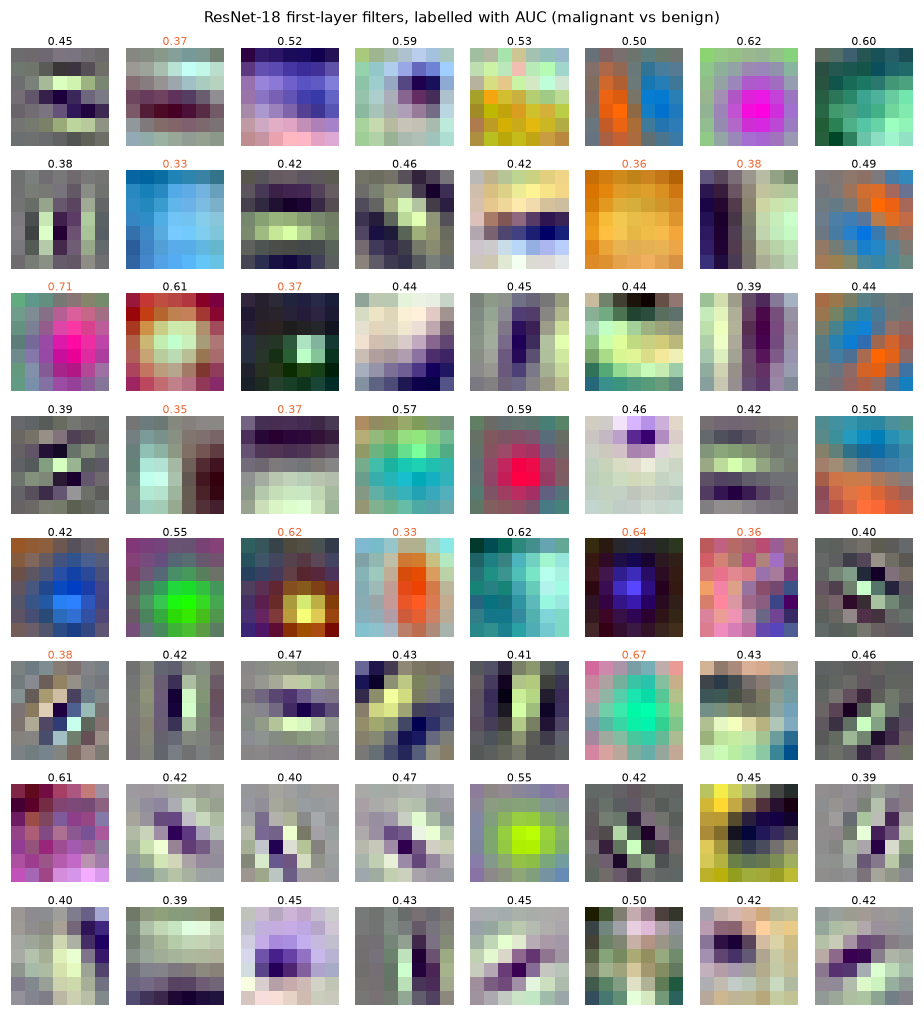

5 most class-separating learned filters (index: AUC): {16: 0.707, 45: 0.672, 9: 0.334, 35: 0.335, 25: 0.355}
most class-separating hand-built filter measure: edge density / contrast  AUC 0.692


In [8]:
if learned is not None:
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    batch = torch.stack([torch.tensor(F.load_rgb(IMG / f"{i}.jpg") / 255.0, dtype=torch.float32).permute(2, 0, 1)
                         for i in sample.derm_id])
    with torch.no_grad():
        resp = torch.nn.functional.conv2d((batch - mean) / std, learned, padding=3)       # (300, 64, 150, 200)
    h, w = resp.shape[-2:]
    energy = resp[..., h // 5: -(h // 5), w // 5: -(w // 5)].abs().mean(dim=(2, 3)).numpy()   # (300, 64)
    auc = np.array([roc_auc_score(is_mal, energy[:, j]) for j in range(64)])
    fig, axes = plt.subplots(8, 8, figsize=(8.5, 9.4))
    for j, ax in enumerate(axes.ravel()):
        k = learned[j].permute(1, 2, 0).numpy()
        ax.imshow((k - k.min()) / (k.max() - k.min()))
        ax.set_title(f"{auc[j]:.2f}", fontsize=7, color=ORANGE if auc[j] > 0.62 or auc[j] < 0.38 else "black", pad=1)
        ax.axis("off")
    plt.suptitle("ResNet-18 first-layer filters, labelled with AUC (malignant vs benign)", fontsize=10)
    plt.tight_layout(); plt.show()
    best = pd.Series(auc).sub(0.5).abs().sort_values(ascending=False).head(5)
    print("5 most class-separating learned filters (index: AUC):",
          {int(j): round(float(auc[j]), 3) for j in best.index})
    hand = filter_table.drop(["brightness (mean)", "contrast (std)"])["AUC (malignant higher)"]
    print(f"most class-separating hand-built filter measure: {hand.sub(0.5).abs().idxmax()}  AUC {hand[hand.sub(0.5).abs().idxmax()]:.3f}")

## 2. Gaussian blur and the meaning of `sigma`

`ndimage.gaussian_filter(img, sigma)` replaces every pixel by a weighted average of its neighbours, with weights
`exp(-x²/2σ²)`: the **bell curve whose standard deviation is `sigma` pixels**. A bigger σ means a wider bell, so each
output pixel averages over a larger neighbourhood and finer detail disappears. Practical consequences:

* `sigma` is in **pixels**, not a fraction of the image: σ = 2 on a 200-px-wide image blurs far more (relative to the image)
  than on a 2,000-px one.
* The window is cut off at `truncate` × σ (default 4), so the kernel radius is `int(4σ + 0.5)` pixels. Roughly 68 % of the
  weight is within ±σ, 95 % within ±2σ, and the half-height width is 2.355 σ.
* It is separable: one 1-D pass along each axis. `sigma` may be a pair `(σ_rows, σ_cols)` to blur the axes differently, and `sigma=0` means no blur.

,kernel radius,window (px),FWHM (px),centre weight
sigma,,,,
0.5,2,5,1.2,0.787
1.0,4,9,2.4,0.399
2.0,8,17,4.7,0.199
4.0,16,33,9.4,0.100
8.0,32,65,18.8,0.050


max |scipy - hand-built kernel| at sigma=2: 0.0


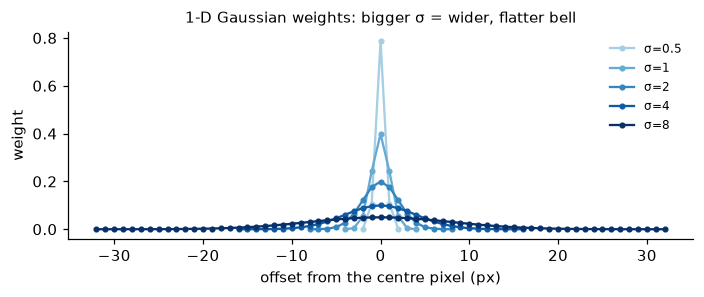

In [9]:
sigmas = [0.5, 1, 2, 4, 8]
rows = []
for s in sigmas:
    k = flt.gaussian_kernel(s)
    rows.append({"sigma": s, "kernel radius": len(k) // 2, "window (px)": len(k), "FWHM (px)": round(2.355 * s, 1),
                 "centre weight": k.max()})
display(pd.DataFrame(rows).set_index("sigma").round(3))

# the hand-built kernel reproduces scipy: blur an image with it, one axis at a time, and compare
g0 = gray_of(sample.derm_id[0])
mine = ndimage.convolve1d(ndimage.convolve1d(g0, flt.gaussian_kernel(2.0), axis=0, mode="reflect"),
                          flt.gaussian_kernel(2.0), axis=1, mode="reflect")
print("max |scipy - hand-built kernel| at sigma=2:", np.abs(ndimage.gaussian_filter(g0, 2.0) - mine).max())

fig, ax = plt.subplots(figsize=(6.5, 2.8))
for s, col in zip(sigmas, plt.cm.Blues(np.linspace(0.35, 1, len(sigmas)))):
    k = flt.gaussian_kernel(s); ax.plot(np.arange(-(len(k) // 2), len(k) // 2 + 1), k, marker="o", ms=3, color=col, label=f"σ={s}")
ax.set_xlabel("offset from the centre pixel (px)"); ax.set_ylabel("weight"); ax.legend(frameon=False, fontsize=8)
ax.set_title("1-D Gaussian weights: bigger σ = wider, flatter bell", fontsize=10)
plt.tight_layout(); plt.show()

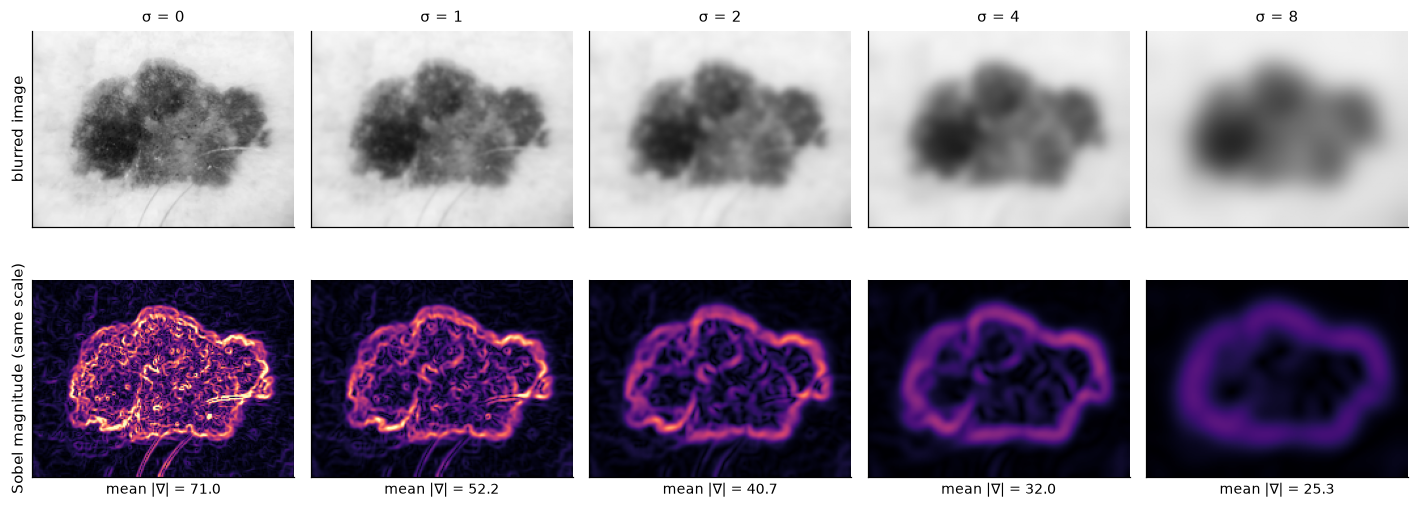

In [10]:
sig_demo = [0, 1, 2, 4, 8]
fig, axes = plt.subplots(2, len(sig_demo), figsize=(13, 5.2))
for c, s in enumerate(sig_demo):
    b = ndimage.gaussian_filter(g0, s) if s else g0
    axes[0, c].imshow(b, cmap="gray", vmin=0, vmax=255); axes[0, c].set_title(f"σ = {s}", fontsize=10)
    m = flt.sobel_gradients(b)[2]
    axes[1, c].imshow(m, cmap="magma", vmax=np.percentile(flt.sobel_gradients(g0)[2], 99))
    axes[1, c].set_xlabel(f"mean |∇| = {core(m).mean():.1f}", fontsize=9)
    for a in axes[:, c]: a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("blurred image"); axes[1, 0].set_ylabel("Sobel magnitude (same scale)")
plt.tight_layout(); plt.show()

**Experiment: edge density as a function of σ, per class.** For each of the 300 sampled lesions, blur at σ ∈ {0 … 8}
and measure the mean Sobel magnitude. Two things to read off: how fast edges vanish, and whether benign and
malignant lesions stay distinguishable once fine texture is blurred away.

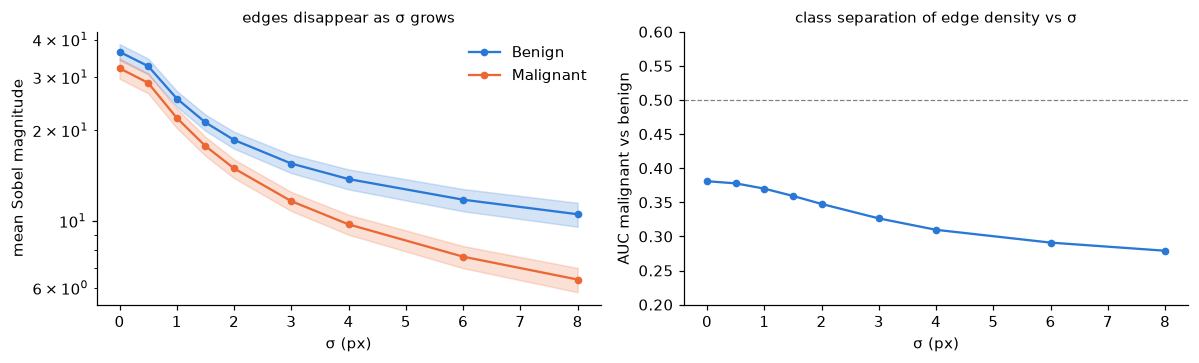

,benign mean,malignant mean,AUC
sigma,,,
0.0,36.413,32.124,0.381
0.5,32.646,28.716,0.378
1.0,25.474,21.973,0.370
1.5,21.230,17.725,0.359
2.0,18.568,14.939,0.348
3.0,15.507,11.632,0.326
4.0,13.772,9.741,0.310
6.0,11.765,7.611,0.291
8.0,10.526,6.391,0.279


In [11]:
SIG = [0, 0.5, 1, 1.5, 2, 3, 4, 6, 8]
dens = np.array([[core(flt.sobel_gradients(ndimage.gaussian_filter(g, s) if s else g)[2]).mean() for s in SIG]
                 for g in grays])                                              # (300, len(SIG))
auc_s = [roc_auc_score(is_mal, dens[:, j]) for j in range(len(SIG))]
sweep = pd.DataFrame({"sigma": SIG, "benign mean": dens[~is_mal].mean(0), "malignant mean": dens[is_mal].mean(0),
                      "AUC": auc_s}).set_index("sigma")
sweep.round(3).to_csv(OUT / "sigma_sweep.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for lab, mask, col in [("Benign", ~is_mal, BLUE), ("Malignant", is_mal, ORANGE)]:
    m, se = dens[mask].mean(0), dens[mask].std(0) / np.sqrt(mask.sum())
    axes[0].plot(SIG, m, marker="o", ms=4, color=col, label=lab); axes[0].fill_between(SIG, m - 2 * se, m + 2 * se, color=col, alpha=0.2)
axes[0].set_yscale("log"); axes[0].set_xlabel("σ (px)"); axes[0].set_ylabel("mean Sobel magnitude"); axes[0].legend(frameon=False)
axes[0].set_title("edges disappear as σ grows", fontsize=10)
axes[1].plot(SIG, auc_s, marker="o", ms=4, color=BLUE); axes[1].axhline(0.5, color="grey", lw=0.8, ls="--")
axes[1].set_xlabel("σ (px)"); axes[1].set_ylabel("AUC malignant vs benign"); axes[1].set_ylim(0.2, 0.6)
axes[1].set_title("class separation of edge density vs σ", fontsize=10)
plt.tight_layout(); plt.show()
sweep.round(3)

## 3. Canny from scratch, and Canny vs Sobel on one image

`flt.canny(gray, sigma, low, high)` follows the four classical steps (every step is its own tested function):

1. **Gaussian blur** (`sigma`) to suppress noise and hair-fine texture.
2. **Sobel gradient** → magnitude and direction at every pixel.
3. **Non-maximum suppression**: keep a pixel only if it is the strongest of its two neighbours *along the gradient direction*
   (direction rounded to 0°, 45°, 90°, 135°). Thick ridges collapse to one-pixel lines.
4. **Double threshold + hysteresis**: pixels above `high` are certain edges, those between `low` and `high` survive only if
   they touch a certain one (`ndimage.label`, 8-connectivity); the rest is dropped. `low` and `high` are fractions of the
   strongest edge in the image, so the result does not depend on exposure.

The comparison image is the benign nevus from the showcase above (the one with the clearest border) at 400×300 px.

ISIC_7559942 - Benign / NV


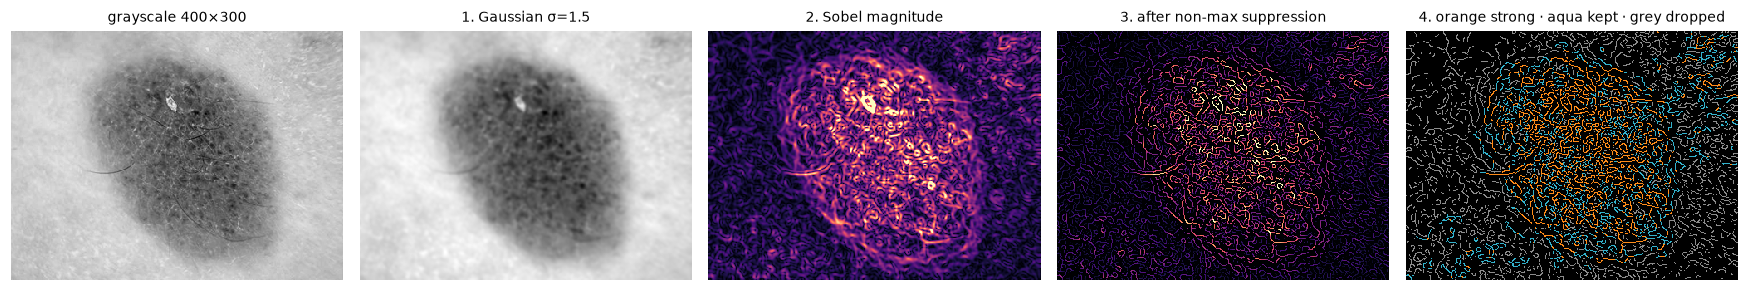

In [12]:
demo_row = cases.iloc[2]            # the benign nevus above: the clearest lesion border of the six
G = gray_of(demo_row.derm_id, size=(400, 300))
print(demo_row.isic_id if "isic_id" in demo_row else demo_row.derm_id, "-", demo_row.diagnosis_1, "/", demo_row.dx)

SIGMA, LOW, HIGH = 1.5, 0.05, 0.15
blur = ndimage.gaussian_filter(G, SIGMA)
gx, gy, mag = flt.sobel_gradients(blur)
thin = flt.non_max_suppression(mag, gx, gy)
peak = thin.max()
strong, weak = thin >= HIGH * peak, thin >= LOW * peak
final = flt.hysteresis(thin, LOW * peak, HIGH * peak)
assert (final == flt.canny(G, SIGMA, LOW, HIGH)).all()                 # the staged code == the function

stage = np.zeros(G.shape + (3,))
stage[weak & ~final] = (0.55, 0.55, 0.55)                              # weak, no strong neighbour: dropped
stage[final] = (0.2, 0.7, 0.8)                                         # kept by hysteresis
stage[strong] = (1.0, 0.55, 0.1)                                       # strong edge pixel
panels = [(G, "gray", "grayscale 400×300", {}), (blur, "gray", f"1. Gaussian σ={SIGMA}", {}),
          (mag, "magma", "2. Sobel magnitude", {"vmax": np.percentile(mag, 99.5)}),
          (thin, "magma", "3. after non-max suppression", {"vmax": np.percentile(mag, 99.5)}),
          (stage, None, "4. orange strong · aqua kept · grey dropped", {})]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.1))
for ax, (im, cm, t, kw) in zip(axes, panels):
    ax.imshow(im, cmap=cm, interpolation="nearest", **kw); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

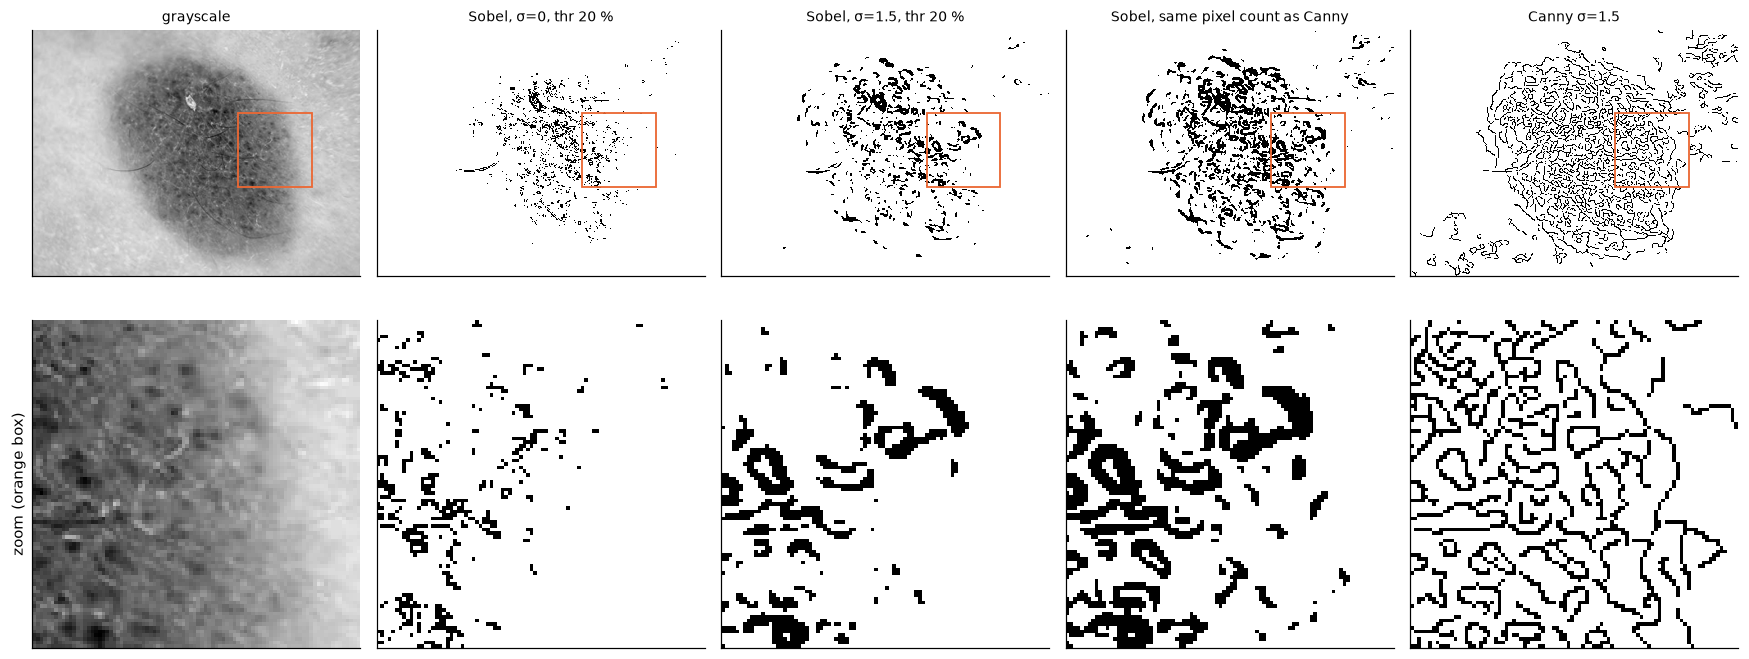

,edge pixels (%),pixels not on a 1-px line (%),connected pieces
"Sobel, σ=0, thr 20 %",2.90,4.94,564.0
"Sobel, σ=1.5, thr 20 %",5.22,28.30,321.0
"Sobel, same pixel count as Canny",10.15,35.66,368.0
Canny σ=1.5,10.15,0.03,309.0


In [13]:
canny_edges = flt.canny(G, SIGMA, LOW, HIGH)
sobel_raw = flt.sobel_edges(G, threshold=0.2, sigma=0)                      # Sobel as taught: threshold 20 % of max
sobel_blur = flt.sobel_edges(G, threshold=0.2, sigma=SIGMA)                # same blur as Canny
thr = np.quantile(mag, 1 - canny_edges.mean())
sobel_budget = mag >= thr                                                    # Sobel with the SAME number of edge pixels as Canny

cross = ndimage.generate_binary_structure(2, 1)
def describe_edges(e):
    n_comp = ndimage.label(e, structure=np.ones((3, 3)))[1]
    thick = ndimage.binary_erosion(e, cross).sum() / max(e.sum(), 1)
    return {"edge pixels (%)": 100 * e.mean(), "pixels not on a 1-px line (%)": 100 * thick, "connected pieces": n_comp}

variants = {"Sobel, σ=0, thr 20 %": sobel_raw, f"Sobel, σ={SIGMA}, thr 20 %": sobel_blur,
            "Sobel, same pixel count as Canny": sobel_budget, f"Canny σ={SIGMA}": canny_edges}
cmp_table = pd.DataFrame({k: describe_edges(v) for k, v in variants.items()}).T
cmp_table.round(2).to_csv(OUT / "canny_vs_sobel.csv")

r0, c0, S = 100, 250, 90                                                     # zoom window on the lesion's right border
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))
axes[0, 0].imshow(G, cmap="gray"); axes[1, 0].imshow(G[r0:r0 + S, c0:c0 + S], cmap="gray", interpolation="nearest")
axes[0, 0].set_title("grayscale", fontsize=9)
for j, (name, e) in enumerate(variants.items(), start=1):
    axes[0, j].imshow(e, cmap="gray_r", interpolation="nearest"); axes[0, j].set_title(name, fontsize=9)
    axes[1, j].imshow(e[r0:r0 + S, c0:c0 + S], cmap="gray_r", interpolation="nearest")
    axes[0, j].add_patch(plt.Rectangle((c0, r0), S, S, fill=False, ec=ORANGE, lw=1.2))
axes[0, 0].add_patch(plt.Rectangle((c0, r0), S, S, fill=False, ec=ORANGE, lw=1.2))
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
axes[1, 0].set_ylabel("zoom (orange box)")
plt.tight_layout(); plt.show()
cmp_table.round(2)

**How the Canny parameters behave.** Top row: a larger σ keeps only the coarse lesion outline and drops the fine texture and
hair. Bottom row (σ = 2): lower thresholds admit weaker edges; higher thresholds keep only the clearest border.

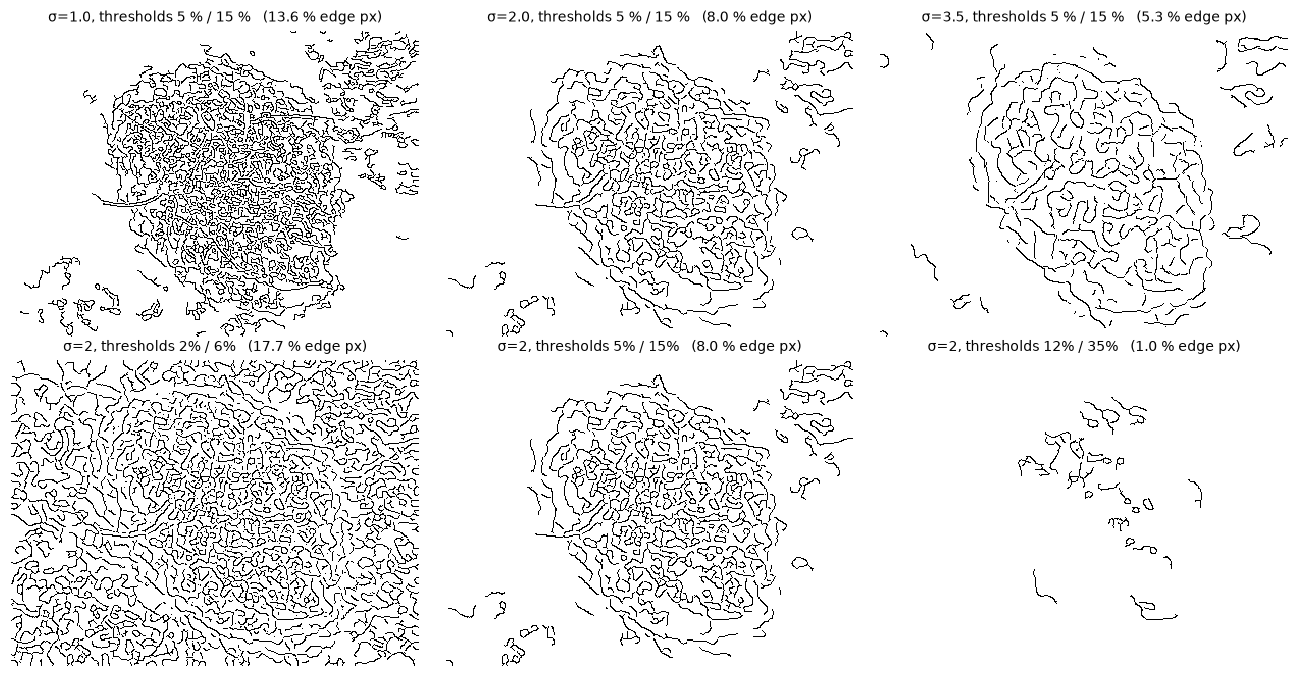

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, s in zip(axes[0], [1.0, 2.0, 3.5]):
    e = flt.canny(G, sigma=s, low=0.05, high=0.15); ax.imshow(e, cmap="gray_r", interpolation="nearest")
    ax.set_title(f"σ={s}, thresholds 5 % / 15 %   ({100 * e.mean():.1f} % edge px)", fontsize=9)
for ax, (lo, hi) in zip(axes[1], [(0.02, 0.06), (0.05, 0.15), (0.12, 0.35)]):
    e = flt.canny(G, sigma=2.0, low=lo, high=hi); ax.imshow(e, cmap="gray_r", interpolation="nearest")
    ax.set_title(f"σ=2, thresholds {lo:.0%} / {hi:.0%}   ({100 * e.mean():.1f} % edge px)", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 5. Answer sheet

**Q1. Do edges and textures differ between malignant and benign lesions?**
Yes on average, but weakly, and mostly through global contrast rather than through "irregular borders".

* On all 3,653 training lesions, malignant lesions have *lower* raw edge density (Sobel AUC 0.40, 95 % CI [0.38, 0.42]) and
  lower Laplacian variance (0.41). That follows from lower image contrast: grayscale standard deviation has a median of 15 for
  malignant vs 26 for benign lesions (AUC 0.30), and malignant images are brighter (AUC 0.69). Many malignant lesions in MILK10k
  (basal and squamous cell carcinoma) are pale and low-contrast, whereas benign nevi and keratoses are dark and pigmented.
* Divide out the contrast and the sign flips: edge density per unit of contrast is *higher* in malignant lesions (AUC 0.70 [0.68, 0.72]),
  i.e. their local structure is busier relative to how much they stand out. Gabor, DoG and Canny measures on the 300-lesion
  sample are weaker still (AUC 0.43 – 0.58).
* Colour is not worse: mean saturation alone reaches AUC 0.62. None of the single filter measures separates the classes
  better than about 0.70, so on their own they are weak classifiers (Session 5 confirms this: the three texture features add little).
* The ResNet-18 filters make the same point. The two most class-separating of the 64 are colour blobs (AUC 0.71 and 0.67);
  the grayscale edge-detector tiles sit at 0.33 – 0.47, again reflecting contrast.
* Confounds to keep in mind: hairs (strong straight edges in every filter, e.g. rows 2, 5 and 6 of the filter figure), the dermatoscope
  rim, and the fact that 69 % of lesions are malignant, so a single 0.60 feature adds little.

**Q2. What does `sigma` do in `scipy.ndimage.gaussian_filter`?**
It is the standard deviation, in pixels, of the Gaussian weights used to average each pixel with its neighbours. The kernel radius is
`int(4σ + 0.5)` (σ = 2 → 8 px, a 17-px window; σ = 8 → 32 px), the half-height width is 2.355 σ, and a hand-built kernel
(`flt.gaussian_kernel`) reproduces scipy exactly (max difference 0.0). Larger σ removes finer detail: mean Sobel magnitude falls from
36.4 (benign) and 32.1 (malignant) at σ = 0 to 10.5 and 6.4 at σ = 8, and the benign/malignant AUC of edge density drifts from
0.38 to 0.28. The class gap therefore **grows** as fine texture is blurred away, which says the difference lives in coarse structure
and contrast, not in fine texture. σ is in pixels, so the same value blurs a 200-px image relative to its content ten times more than a 2,000-px one.

**Q3. Canny vs Sobel on one image** (benign nevus, 400×300 px, Canny σ = 1.5, thresholds 5 % / 15 % of the peak gradient):

| | edge pixels | pixels not on a 1-px line | connected pieces |
|---|---|---|---|
| Sobel, σ = 0, threshold 20 % | 2.9 % | 4.9 % | 564 |
| Sobel, σ = 1.5, threshold 20 % | 5.2 % | 28.3 % | 321 |
| Sobel with the same pixel count as Canny | 10.2 % | 35.7 % | 368 |
| **Canny σ = 1.5** | 10.2 % | **0.03 %** | 309 |

Sobel marks every pixel whose gradient exceeds one global threshold, so edges come out as thick blobs once the image is blurred
(28 – 36 % of its pixels are not on a one-pixel line) or as broken specks when it is not (564 fragments). Canny's non-maximum
suppression reduces every ridge to one pixel, and hysteresis keeps weak pixels that continue a strong edge and drops isolated ones,
so it gives thin, continuous contours at the same pixel budget. The costs: three parameters (σ, low, high), more computation, and
it still traces everything that looks like an edge: at σ = 1.5 the lesion interior is a tangle of pigment-network contours and hairs
survive. A larger σ (3.5 in the last figure) is what leaves the lesion outline and discards the texture.